# Introducción a las API REST con Python
**Taller de Programación Aplicada · Primer año**  
Profesora Mónica Otero · Material actualizado el 2 de noviembre de 2026

Hoy escribiremos un programa que pide datos a otro programa. Primero usaremos una **API local de cafetería** y después consultaremos servicios públicos.

**Al finalizar podrás:** identificar cliente, servidor y recurso; interpretar una petición y su respuesta; usar `requests`; transformar JSON en estructuras de Python; distinguir `GET`, `POST`, `PUT`, `PATCH` y `DELETE`.

**Uso en Colab:** sube este archivo `.ipynb`, conéctate a un entorno Python y ejecuta las celdas de arriba abajo. No requiere GPU, cuentas en servicios externos ni claves API. Las celdas con código se ejecutan con el botón de reproducción. Cada estudiante tendrá su propio catálogo.

**Ruta de 90 minutos**

| Bloque | Tiempo orientativo | Actividad |
|---|---:|---|
| Conceptos y preparación, secciones 1–2 | 15 min | Identificar quién pide y quién responde |
| GET, JSON y parámetros, secciones 3–5 | 25 min | Leer y filtrar productos |
| Operaciones y errores, secciones 6–7 | 25 min | Crear, modificar, eliminar e interpretar errores |
| Servicios externos, sección 8 | 10 min | Ver el ejemplo original y el meteorológico |
| Práctica y cierre, secciones 9–10 | 15 min | Resolver y explicar |

Si dispones de 60 minutos, deja `PUT`, los errores adicionales y el puente con Pandas como ampliación. Las soluciones están al final.

## 1. Qué problema resuelve una API
Una **API**, interfaz de programación de aplicaciones, especifica cómo un programa puede utilizar funciones o datos de otro. Aquí trabajaremos con API web.

Imagina una cafetería. El programa necesita consultar los productos y sus precios. La API define las rutas disponibles, las operaciones aceptadas y el formato de las respuestas.

| Término | En este laboratorio |
|---|---|
| Cliente | Nuestro código Python, que envía peticiones |
| Servidor | El programa que recibe peticiones y administra el catálogo |
| Recurso | Un producto, por ejemplo el producto con identificador `1` |
| Representación | Los datos que describen el producto, aquí en JSON |
| URL | La dirección usada para hacer la petición |
| Endpoint | Un punto de acceso de la API, por ejemplo `GET /productos/1` |
| Petición o request | Lo que envía el cliente: método, dirección, cabeceras y, a veces, cuerpo |
| Respuesta o response | Lo que devuelve el servidor: estado, cabeceras y, a veces, cuerpo |
| HTTP | Protocolo para intercambiar estas peticiones y respuestas |
| HTTPS | HTTP sobre una conexión protegida mediante TLS |

**Pregunta antes del código:** cuando Python hace `GET /productos/1`, ¿quién es el cliente y quién decide qué responder?

### REST, API y microservicios
**REST** (*Representational State Transfer*) es un estilo arquitectónico. En una API HTTP orientada a recursos se usan direcciones para identificarlos y métodos HTTP para expresar las operaciones. JSON es un formato habitual de intercambio; REST admite otros formatos.

**Sin estado de sesión del cliente** significa que cada petición debe aportar la información necesaria para interpretarla. El servidor puede conservar productos en una base de datos: guardar recursos y recordar una conversación del cliente son conceptos diferentes.

Los **microservicios** organizan una aplicación en servicios que pueden desarrollarse y desplegarse por separado. Pueden comunicarse mediante API HTTP, mensajería u otros mecanismos. Una API también puede pertenecer a una aplicación monolítica. La independencia ayuda a aislar fallos, pero las dependencias entre servicios pueden propagarlos.

**Alcance de hoy:** la API del laboratorio es una API HTTP didáctica para practicar recursos, métodos y representaciones. Una arquitectura REST completa incluye restricciones adicionales, como caché, capas e hipermedia, que quedan como ampliación.

## 2. Preparación
Primero importamos las bibliotecas. `requests` permite enviar peticiones HTTP y `json` permite convertir entre datos de Python y texto JSON.

In [1]:
try:
    import requests
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'requests'])
    import requests

import json
print('Bibliotecas disponibles.')

Bibliotecas disponibles.


### Encender el servidor de práctica
Ejecuta la siguiente celda y continúa. **No necesitas estudiar su implementación hoy**: prepara el servidor y sus datos; nosotros programaremos el cliente.

`127.0.0.1` indica el propio entorno de ejecución. En Colab, cliente y servidor estarán dentro de la misma máquina virtual. Las peticiones HTTP son reales. Esta URL local se usa desde el código del cuaderno, no desde el navegador de tu computador.

Los cambios se conservarán mientras este servidor siga activo. Volver a ejecutar esta celda reinicia el catálogo. Los precios son ejemplos en pesos chilenos.

In [2]:
#@title Preparar la API de práctica (ejecutar; no es necesario estudiar este código hoy)
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from urllib.parse import urlparse, parse_qs
from copy import deepcopy
import threading
import math
import time
import os

# Las peticiones a este servidor permanecen dentro del entorno de ejecución.
os.environ['NO_PROXY'] = ','.join(filter(None, [os.environ.get('NO_PROXY', ''), '127.0.0.1', 'localhost']))
if '_servidor_clase' in globals():
    _servidor_clase.shutdown()
    _servidor_clase.server_close()

_productos_iniciales = {
    1: {'id': 1, 'nombre': 'Café', 'precio': 1200, 'categoria': 'bebida'},
    2: {'id': 2, 'nombre': 'Agua', 'precio': 800, 'categoria': 'bebida'},
    3: {'id': 3, 'nombre': 'Sándwich', 'precio': 2500, 'categoria': 'comida'},
    4: {'id': 4, 'nombre': 'Fruta', 'precio': 600, 'categoria': 'comida'},
}
_estado_clase = {}

def reiniciar_catalogo():
    """Restablece los datos del laboratorio; esta función no es un método HTTP."""
    _estado_clase['productos'] = deepcopy(_productos_iniciales)
    _estado_clase['siguiente_id'] = 5

reiniciar_catalogo()

class _APIClase(BaseHTTPRequestHandler):
    def log_message(self, *args):
        pass

    def responder(self, codigo, dato=None, cabeceras=None, texto=False):
        if codigo == 204:
            contenido = b''
        elif texto:
            contenido = dato.encode('utf-8')
        else:
            contenido = json.dumps(dato, ensure_ascii=False, allow_nan=False).encode('utf-8')
        self.send_response(codigo)
        if codigo != 204:
            self.send_header('Content-Type', 'text/plain; charset=utf-8' if texto else 'application/json; charset=utf-8')
        self.send_header('Content-Length', str(len(contenido)))
        for k, v in (cabeceras or {}).items():
            self.send_header(k, v)
        self.end_headers()
        try:
            if self.command != 'HEAD':
                self.wfile.write(contenido)
        except (BrokenPipeError, ConnectionResetError):
            pass

    def leer_json(self):
        if self.headers.get('Content-Type', '').split(';')[0] != 'application/json':
            raise ValueError('Envía el cuerpo como JSON: usa json= en requests.')
        contenido = self.rfile.read(int(self.headers.get('Content-Length', '0')))
        dato = json.loads(contenido.decode('utf-8'))
        if not isinstance(dato, dict):
            raise ValueError('Se esperaba un objeto JSON con campos de un producto.')
        return dato

    def validar(self, dato, parcial=False):
        campos = {'nombre', 'precio', 'categoria'}
        if set(dato) - campos:
            raise ValueError('Campos permitidos: nombre, precio, categoria. El servidor asigna id.')
        if not parcial and set(dato) != campos:
            raise ValueError('En esta API se requieren nombre, precio y categoria.')
        for campo in ('nombre', 'categoria'):
            if campo in dato and (not isinstance(dato[campo], str) or not dato[campo].strip()):
                raise ValueError(f'{campo} debe ser un texto no vacío.')
        if 'precio' in dato:
            p = dato['precio']
            if isinstance(p, bool) or not isinstance(p, (int, float)) or not math.isfinite(p) or p < 0:
                raise ValueError('precio debe ser un número finito mayor o igual que cero.')

    def atender(self):
        ruta = urlparse(self.path)
        metodo = self.command
        partes = ruta.path.strip('/').split('/')
        productos = _estado_clase['productos']
        if metodo == 'GET' and ruta.path == '/texto':
            return self.responder(200, 'Esta respuesta es texto, no JSON.', texto=True)
        if metodo == 'GET' and ruta.path == '/demo/error':
            return self.responder(500, {'error': 'Error de servidor preparado para la demostración.'})
        if metodo == 'GET' and ruta.path == '/demo/lento':
            time.sleep(0.3)
            return self.responder(200, {'mensaje': 'El servidor terminó de responder.'})
        if not (len(partes) in (1, 2) and partes[0] == 'productos'):
            return self.responder(404, {'error': 'Ruta inexistente.'})
        identificador = None
        if len(partes) == 2:
            if not partes[1].isdigit():
                return self.responder(404, {'error': 'Identificador inexistente.'})
            identificador = int(partes[1])
        permitidos = ['GET', 'HEAD', 'POST', 'OPTIONS'] if identificador is None else ['GET', 'HEAD', 'PUT', 'PATCH', 'DELETE', 'OPTIONS']
        if metodo == 'OPTIONS':
            return self.responder(204, cabeceras={'Allow': ', '.join(permitidos)})
        if metodo not in permitidos:
            return self.responder(405, {'error': 'Método no permitido en esta ruta.'}, {'Allow': ', '.join(permitidos)})
        if identificador is not None and identificador not in productos:
            return self.responder(404, {'error': 'Producto no encontrado.', 'id': identificador})
        try:
            if metodo in ('GET', 'HEAD'):
                if identificador is not None:
                    return self.responder(200, productos[identificador])
                datos = list(productos.values())
                parametros = parse_qs(ruta.query)
                if 'categoria' in parametros:
                    datos = [p for p in datos if p['categoria'] == parametros['categoria'][0]]
                if 'max_precio' in parametros:
                    maximo = float(parametros['max_precio'][0])
                    if not math.isfinite(maximo) or maximo < 0:
                        raise ValueError('max_precio debe ser un número finito no negativo.')
                    datos = [p for p in datos if p['precio'] <= maximo]
                return self.responder(200, sorted(datos, key=lambda p: p['id']))
            if metodo == 'DELETE':
                del productos[identificador]
                return self.responder(204)
            dato = self.leer_json()
            self.validar(dato, parcial=(metodo == 'PATCH'))
            if metodo == 'POST':
                identificador = _estado_clase['siguiente_id']
                _estado_clase['siguiente_id'] += 1
                productos[identificador] = {'id': identificador, **dato}
                return self.responder(201, productos[identificador], {'Location': f'/productos/{identificador}'})
            if metodo == 'PUT':
                productos[identificador] = {'id': identificador, **dato}
            else:
                productos[identificador].update(dato)
            return self.responder(200, productos[identificador])
        except (ValueError, UnicodeDecodeError) as error:
            return self.responder(400, {'error': str(error)})

    do_GET = atender
    do_HEAD = atender
    do_POST = atender
    do_PUT = atender
    do_PATCH = atender
    do_DELETE = atender
    do_OPTIONS = atender

_servidor_clase = ThreadingHTTPServer(('127.0.0.1', 0), _APIClase)
_servidor_clase.daemon_threads = True
_hilo_clase = threading.Thread(target=_servidor_clase.serve_forever, daemon=True)
_hilo_clase.start()
BASE_URL = f'http://127.0.0.1:{_servidor_clase.server_port}'
print('API de práctica lista. BASE_URL =', BASE_URL)
print('Recursos disponibles: /productos y /productos/<id>. Datos iniciales: 4 productos.')

API de práctica lista. BASE_URL = http://127.0.0.1:32991
Recursos disponibles: /productos y /productos/<id>. Datos iniciales: 4 productos.


## 3. Primera petición con GET
`GET` solicita una representación del recurso. Observa tres elementos: la URL, la llamada a `requests.get()` y el objeto de respuesta.

**Predice:** ¿pediremos un producto o toda la colección?

In [3]:
url = BASE_URL + '/productos/1'
respuesta = requests.get(url, timeout=5)

print('Método enviado:', respuesta.request.method)
print('URL:', respuesta.url)
print('Código HTTP:', respuesta.status_code)
print('Content-Type:', respuesta.headers.get('Content-Type'))
print('Cuerpo como texto:', respuesta.text)

Método enviado: GET
URL: http://127.0.0.1:32991/productos/1
Código HTTP: 200
Content-Type: application/json; charset=utf-8
Cuerpo como texto: {"id": 1, "nombre": "Café", "precio": 1200, "categoria": "bebida"}


**Qué observar:** la respuesta contiene el producto `1` y el código `200`. `Content-Type` describe el formato del cuerpo. El objeto `respuesta` contiene más información que los datos del producto.

| Expresión | Qué es | Qué proporciona |
|---|---|---|
| `requests.get(...)` | Función de la biblioteca | Envía GET y devuelve un objeto `Response` |
| `respuesta.status_code` | Atributo, sin paréntesis | Código HTTP entero |
| `respuesta.headers` | Atributo | Cabeceras de respuesta |
| `respuesta.text` | Atributo | Cuerpo interpretado como texto |
| `respuesta.json()` | Método, con paréntesis | Decodifica el cuerpo JSON como un objeto Python |
| `respuesta.raise_for_status()` | Método | Lanza `HTTPError` ante estados 4xx o 5xx |

`timeout=5` configura la espera de conexión/lectura. No equivale a un cronómetro total para toda la ejecución.

In [4]:
respuesta.raise_for_status()
producto = respuesta.json()

print('Tipo de respuesta:', type(respuesta).__name__)
print('Tipo de producto:', type(producto).__name__)
print('Nombre:', producto['nombre'])
print('Precio:', producto['precio'])

Tipo de respuesta: Response
Tipo de producto: dict
Nombre: Café
Precio: 1200


### Un recurso y una colección
La forma de la respuesta depende del contrato de la API. En nuestro caso, `/productos/1` devuelve un objeto y `/productos` devuelve un arreglo.

In [5]:
respuesta_lista = requests.get(BASE_URL + '/productos', timeout=5)
respuesta_lista.raise_for_status()
productos = respuesta_lista.json()

print('Tipo de la colección:', type(productos).__name__)
print('Cantidad:', len(productos))
for elemento in productos:
    print(elemento['id'], elemento['nombre'], elemento['precio'])

Tipo de la colección: list
Cantidad: 4
1 Café 1200
2 Agua 800
3 Sándwich 2500
4 Fruta 600


## 4. JSON y Python
JSON es texto para intercambiar datos. Cuando lo decodificamos, obtenemos objetos de Python.

| En JSON | En Python |
|---|---|
| Objeto `{...}` | `dict` |
| Arreglo `[...]` | `list` |
| `true`, `false` | `True`, `False` |
| `null` | `None` |

Por eso `.json()` puede devolver un diccionario, una lista u otro tipo compatible, según el contenido. Las claves de los objetos JSON usan comillas dobles.

In [6]:
dato_python = {'nombre': 'Té', 'disponible': True, 'nota': None}
texto_json = json.dumps(dato_python, indent=2, sort_keys=True, ensure_ascii=False)

print(texto_json)
print('Tipo serializado:', type(texto_json).__name__)

dato_recuperado = json.loads(texto_json)
print('Tipo decodificado:', type(dato_recuperado).__name__)
print('¿Se conservaron los datos?', dato_recuperado == dato_python)

{
  "disponible": true,
  "nombre": "Té",
  "nota": null
}
Tipo serializado: str
Tipo decodificado: dict
¿Se conservaron los datos? True


`json.dumps()` serializa datos como texto. `indent` controla la presentación, `sort_keys` ordena las claves y `ensure_ascii=False` deja visibles los caracteres como `é`. `json.loads()` hace la conversión inversa desde texto. Cambiar la presentación del JSON no cambia los datos del servidor.

**Comprueba:** ¿qué diferencia hay entre `producto`, `respuesta.text` y `json.dumps(producto)`?

## 5. Parámetros y partes de una petición
El identificador va en la **ruta** (`/productos/1`). Un filtro puede ir en la **consulta**, después de `?`. Usaremos `params=` para construirla.

**Contrato de nuestra API:** `/productos` acepta `categoria` y `max_precio`. Estos nombres no son universales: cada API los documenta.

In [7]:
filtros = {'categoria': 'bebida', 'max_precio': 1000}
respuesta_filtro = requests.get(BASE_URL + '/productos', params=filtros, timeout=5)
respuesta_filtro.raise_for_status()

print('URL construida:', respuesta_filtro.url)
print('Resultado:', respuesta_filtro.json())

URL construida: http://127.0.0.1:32991/productos?categoria=bebida&max_precio=1000
Resultado: [{'id': 2, 'nombre': 'Agua', 'precio': 800, 'categoria': 'bebida'}]


El resultado esperado es **Agua**. El filtro lo aplica el servidor. Si no hay coincidencias, esta API devuelve una lista vacía con `200`: la consulta fue válida.

| Parte | Ejemplo | En Requests |
|---|---|---|
| Método | GET, POST | `requests.get()`, `requests.post()` |
| Ruta | `/productos/1` | Dentro de `url` |
| Consulta | `?categoria=bebida` | `params={...}` |
| Cabeceras | `Accept: application/json` | `headers={...}` |
| Cuerpo | Datos del producto que se enviará | `json={...}` |

`Accept` indica qué formato acepta el cliente. `Content-Type` describe el formato del cuerpo enviado. Usaremos `json=` para que Requests codifique los datos y prepare su cabecera.

## 6. Crear, reemplazar, modificar y eliminar
Estas son asociaciones habituales en una API de recursos. `POST` también puede servir para otras operaciones de procesamiento, según la API.

| Método HTTP | Objetivo en esta API | Función Python |
|---|---|---|
| GET | Consultar | `requests.get()` |
| POST | Crear un producto | `requests.post()` |
| PUT | Reemplazar sus campos editables | `requests.put()` |
| PATCH | Modificar algunos campos | `requests.patch()` |
| DELETE | Eliminarlo | `requests.delete()` |

Trabajaremos sobre un producto creado para esta demostración. **Aquí los cambios sí se conservan en memoria**, y los verificaremos con nuevas peticiones GET.

### POST: crear
El servidor asigna el identificador. Enviamos un diccionario mediante `json=`.

In [8]:
nuevo = {'nombre': 'Jugo', 'precio': 1500, 'categoria': 'bebida'}
respuesta_post = requests.post(
    BASE_URL + '/productos',
    json=nuevo,
    headers={'Accept': 'application/json'},
    timeout=5,
)
respuesta_post.raise_for_status()
creado = respuesta_post.json()
id_creado = creado['id']
url_creado = BASE_URL + '/productos/' + str(id_creado)

print('Estado:', respuesta_post.status_code)
print('Content-Type enviado:', respuesta_post.request.headers.get('Content-Type'))
print('Location:', respuesta_post.headers.get('Location'))
print('Creado:', creado)
verificacion = requests.get(url_creado, timeout=5)
verificacion.raise_for_status()
print('Verificación con GET:', verificacion.json())

Estado: 201
Content-Type enviado: application/json
Location: /productos/5
Creado: {'id': 5, 'nombre': 'Jugo', 'precio': 1500, 'categoria': 'bebida'}
Verificación con GET: {'id': 5, 'nombre': 'Jugo', 'precio': 1500, 'categoria': 'bebida'}


Esperamos `201 Created`. La cabecera `Location` señala el recurso creado. La petición GET posterior muestra que el servidor lo conservó.

### PUT: reemplazar
En **esta API**, `PUT` exige `nombre`, `precio` y `categoria`. El identificador permanece en la ruta. Comprueba cuáles campos cambian.

In [9]:
reemplazo = {'nombre': 'Batido', 'precio': 2200, 'categoria': 'bebida'}
respuesta_put = requests.put(url_creado, json=reemplazo, timeout=5)
respuesta_put.raise_for_status()
print('Estado:', respuesta_put.status_code)
print('Después de PUT:', respuesta_put.json())

Estado: 200
Después de PUT: {'id': 5, 'nombre': 'Batido', 'precio': 2200, 'categoria': 'bebida'}


### PATCH: modificar una parte
Enviaremos solo el precio. El nombre y la categoría deben conservarse. El formato de las modificaciones depende de cada API; aquí usamos un objeto JSON con los campos que cambian.

In [10]:
respuesta_patch = requests.patch(url_creado, json={'precio': 1900}, timeout=5)
respuesta_patch.raise_for_status()
print('Estado:', respuesta_patch.status_code)
print('Después de PATCH:', respuesta_patch.json())

Estado: 200
Después de PATCH: {'id': 5, 'nombre': 'Batido', 'precio': 1900, 'categoria': 'bebida'}


### DELETE: eliminar
Esta API devuelve `204 No Content`. Esta respuesta no tiene cuerpo y no debe procesarse con `.json()`.

In [11]:
respuesta_delete = requests.delete(url_creado, timeout=5)
respuesta_delete.raise_for_status()
print('Estado de DELETE:', respuesta_delete.status_code)
print('Cuerpo:', repr(respuesta_delete.text))

verificacion_borrado = requests.get(url_creado, timeout=5)
print('Estado del GET posterior:', verificacion_borrado.status_code)
print('Mensaje:', verificacion_borrado.json())

Estado de DELETE: 204
Cuerpo: ''
Estado del GET posterior: 404
Mensaje: {'error': 'Producto no encontrado.', 'id': 5}


**Discusión:** ¿qué evidencia tenemos de que POST creó el producto y DELETE lo eliminó? ¿Qué diferencias observaste entre PUT y PATCH?

## 7. Interpretar respuestas y errores

| Estado | Significado orientativo |
|---|---|
| 200 | Petición atendida correctamente |
| 201 | Se crearon recursos |
| 204 | Éxito sin cuerpo de respuesta |
| 400 | La petición contiene datos no aceptados |
| 401 | Se requiere autenticación válida |
| 403 | El acceso está prohibido |
| 404 | Recurso o ruta no encontrados |
| 405 | Método no permitido en esa ruta |
| 429 | Se superó un límite de peticiones; consultar la política de la API |
| 500 | Error interno del servidor |

Un estado es información sobre la petición. El detalle del error puede venir en el cuerpo. **Que `.json()` funcione no implica éxito HTTP.**

In [12]:
respuesta_error = requests.get(BASE_URL + '/productos/9999', timeout=5)
print('Estado:', respuesta_error.status_code)
print('El cuerpo también es JSON:', respuesta_error.json())

try:
    respuesta_error.raise_for_status()
except requests.exceptions.HTTPError:
    print('raise_for_status() detectó el error HTTP. Revisa la URL y el identificador.')

Estado: 404
El cuerpo también es JSON: {'error': 'Producto no encontrado.', 'id': 9999}
raise_for_status() detectó el error HTTP. Revisa la URL y el identificador.


In [13]:
datos_invalidos = {'nombre': 'Pan', 'precio': -100, 'categoria': 'comida'}
respuesta_invalida = requests.post(BASE_URL + '/productos', json=datos_invalidos, timeout=5)
print('Estado:', respuesta_invalida.status_code)
print('Detalle:', respuesta_invalida.json())

Estado: 400
Detalle: {'error': 'precio debe ser un número finito mayor o igual que cero.'}


### Ampliación: otros errores que conviene distinguir
`500` describe un problema del servidor. Un error al decodificar JSON significa que el cuerpo no tiene el formato esperado. Un *timeout* indica que la espera configurada se agotó; puede ocurrir sin que recibamos un estado HTTP.

In [14]:
error_servidor = requests.get(BASE_URL + '/demo/error', timeout=5)
print('Error preparado en el servidor:', error_servidor.status_code)

respuesta_texto = requests.get(BASE_URL + '/texto', timeout=5)
try:
    respuesta_texto.json()
except requests.exceptions.JSONDecodeError:
    print('La respuesta es texto, no JSON:', respuesta_texto.text)

try:
    requests.get(BASE_URL + '/demo/lento', timeout=0.05)
except requests.exceptions.Timeout:
    print('La espera se agotó. No es lo mismo que recibir un 404.')

Error preparado en el servidor: 500
La respuesta es texto, no JSON: Esta respuesta es texto, no JSON.
La espera se agotó. No es lo mismo que recibir un 404.


### Una función propia para reutilizar consultas
Después de entender las llamadas, podemos agruparlas. Esta función devuelve datos Python; si el servidor responde con un error HTTP, `raise_for_status()` lo comunica al código que la llamó.

In [15]:
def obtener_producto(id_producto):
    url_producto = BASE_URL + '/productos/' + str(id_producto)
    respuesta = requests.get(url_producto, timeout=5)
    respuesta.raise_for_status()
    return respuesta.json()

print(obtener_producto(2))

{'id': 2, 'nombre': 'Agua', 'precio': 800, 'categoria': 'bebida'}


## 8. Conectar con las API de las diapositivas
### JSONPlaceholder y el puente con Pandas
Este es el servicio de la diapositiva 11. Devuelve datos ficticios de publicaciones. Añadimos tiempo de espera y comprobación de estado. Si el servicio no responde, la celda identifica explícitamente un ejemplo fijo para continuar.

**Importante:** JSONPlaceholder simula las respuestas de escritura; crear o modificar allí no cambia sus GET posteriores. Para observar cambios persistentes, usamos el servidor local de las secciones anteriores.

In [16]:
import pandas as pd

try:
    respuesta_publica = requests.get('https://jsonplaceholder.typicode.com/posts/1', timeout=8)
    respuesta_publica.raise_for_status()
    publicacion = respuesta_publica.json()
    if not isinstance(publicacion, dict) or 'title' not in publicacion:
        raise ValueError('La respuesta no tiene la estructura esperada.')
    origen_publicacion = 'Consulta en línea a JSONPlaceholder'
except (requests.exceptions.RequestException, ValueError) as error:
    publicacion = {'userId': 1, 'id': 1, 'title': 'Publicación de ejemplo', 'body': 'Dato fijo para practicar.'}
    origen_publicacion = 'EJEMPLO FIJO: el servicio externo no respondió correctamente.'
    print(type(error).__name__)

print(origen_publicacion)
display(pd.DataFrame([publicacion]))

Consulta en línea a JSONPlaceholder


,userId,id,title,body
0,1,1,sunt aut facere repellat provident occaecati e...,quia et suscipit\nsuscipit recusandae consequu...


`publicacion` es un diccionario. `[publicacion]` es una lista que contiene ese diccionario y produce una fila. Si la API devuelve una lista de diccionarios, se usa directamente esa lista.

In [17]:
respuesta_tabla = requests.get(BASE_URL + '/productos', timeout=5)
respuesta_tabla.raise_for_status()
df_productos = pd.DataFrame(respuesta_tabla.json())
display(df_productos)

,id,nombre,precio,categoria
0,1,Café,1200,bebida
1,2,Agua,800,bebida
2,3,Sándwich,2500,comida
3,4,Fruta,600,comida


### Meteorología sin clave API
Consultaremos **Open-Meteo** para Santiago. Trabajaremos con latitud y longitud, no con el nombre de la ciudad. El contrato documenta los nombres de los parámetros y las unidades de salida.

Las condiciones de Open-Meteo provienen de modelos meteorológicos. Si la consulta falla, usaremos un ejemplo fijo claramente rotulado; sus valores no representan el clima actual.

In [18]:
def consultar_clima(latitud, longitud):
    parametros = {
        'latitude': latitud,
        'longitude': longitud,
        'current': 'temperature_2m,relative_humidity_2m,wind_speed_10m',
        'timezone': 'America/Santiago',
    }
    respuesta = requests.get('https://api.open-meteo.com/v1/forecast', params=parametros, timeout=8)
    respuesta.raise_for_status()
    return respuesta.json()

try:
    clima = consultar_clima(-33.45, -70.65)
    if not isinstance(clima, dict) or not isinstance(clima.get('current'), dict):
        raise ValueError('No se encontró el bloque current esperado.')
    if 'temperature_2m' not in clima['current'] or 'current_units' not in clima:
        raise ValueError('Faltan variables o unidades esperadas.')
    origen_clima = 'Consulta en línea a Open-Meteo'
except (requests.exceptions.RequestException, ValueError) as error:
    clima = {
        'current': {'time': '2026-01-01T12:00', 'temperature_2m': 22.5, 'relative_humidity_2m': 45, 'wind_speed_10m': 8.0},
        'current_units': {'time': 'iso8601', 'temperature_2m': '°C', 'relative_humidity_2m': '%', 'wind_speed_10m': 'km/h'},
    }
    origen_clima = 'EJEMPLO FIJO: no son datos del clima actual.'
    print('No se obtuvo la respuesta externa:', type(error).__name__)

print(origen_clima)
print('Momento representado:', clima['current']['time'])
print('Temperatura:', clima['current']['temperature_2m'], clima['current_units']['temperature_2m'])
print(json.dumps(clima['current'], indent=2, ensure_ascii=False))
display(pd.DataFrame([clima['current']]))

Consulta en línea a Open-Meteo
Momento representado: 2026-11-02T11:30
Temperatura: 20.2 °C
{
  "time": "2026-11-02T11:30",
  "interval": 900,
  "temperature_2m": 20.2,
  "relative_humidity_2m": 57,
  "wind_speed_10m": 4.3
}


,time,interval,temperature_2m,relative_humidity_2m,wind_speed_10m
0,2026-11-02T11:30,900,20.2,57,4.3


**Preguntas:** ¿qué parte de `clima` contiene las unidades? ¿Qué cambia para consultar otra ubicación? ¿Por qué una temperatura fija escrita en el código no debe presentarse como una medición actual?

**Autenticación, para otra clase:** algunas API requieren una clave o token. El mecanismo lo define cada servicio. En Colab se pueden guardar credenciales en el panel de secretos y leerlas mediante `google.colab.userdata`. Evita escribir claves reales en celdas o diapositivas compartidas. Estos ejemplos no necesitan credenciales.

### Ampliación opcional: de la API a una visualización
Aquí se recuperan datos de la API y se representan con herramientas que ya conocen. El gráfico describe los precios ficticios del catálogo.

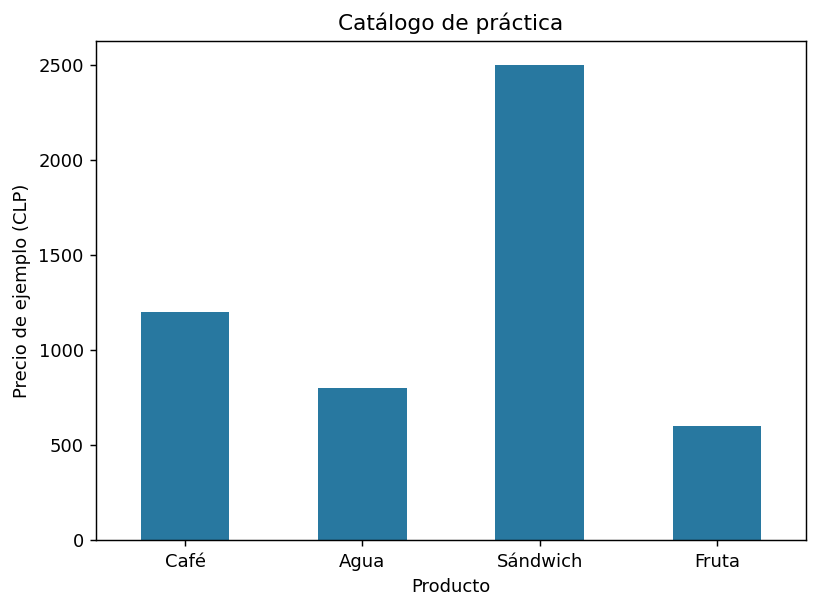

In [19]:
import matplotlib.pyplot as plt

ax = df_productos.plot.bar(x='nombre', y='precio', legend=False, color='#2878A0')
ax.set_title('Catálogo de práctica')
ax.set_ylabel('Precio de ejemplo (CLP)')
ax.set_xlabel('Producto')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Práctica guiada
Ejecuta esta celda para volver a los cuatro productos iniciales. Después resuelve sin mirar las soluciones.

In [20]:
reiniciar_catalogo()
print('Catálogo reiniciado para los ejercicios.')

Catálogo reiniciado para los ejercicios.


### Ejercicio 1. Consultar un recurso
Pide el producto `2`, comprueba el estado y muestra únicamente su nombre y precio. Explica por qué necesitas `.json()` para acceder a sus campos.

In [21]:
# Escribe aquí tu solución del ejercicio 1.

### Ejercicio 2. Enviar filtros
Consulta la colección usando `params=` para obtener bebidas de precio menor o igual que 1000. Muestra la URL construida, los resultados y su cantidad.

In [22]:
# Escribe aquí tu solución del ejercicio 2.

### Ejercicio 3. Verificar cambios
Crea un producto llamado `Granola`, precio 1500 y categoría `comida`. Conserva el identificador que devuelve el servidor. Cambia solo su precio a 1300 mediante PATCH, comprueba el cambio con GET y elimínalo con DELETE. Un GET posterior debe devolver `404`.

In [23]:
# Escribe aquí tu solución del ejercicio 3.

### Ejercicio 4. Encontrar y explicar dos errores
Este fragmento se muestra como texto para poder discutirlo antes de ejecutarlo:

```python
respuesta = requests.get(BASE_URL + '/productos/2', timeout=5)
datos = respuesta.json
print(datos['nombre'])
print(respuesta.status_code())
```

Corrige los paréntesis y explica cuáles expresiones son métodos y cuáles son atributos.

In [24]:
# Escribe aquí el fragmento corregido y tus explicaciones como comentarios.

## 10. Cierre y comprobación de comprensión
Responde en una frase cada pregunta:

1. ¿Cuál es el cliente y cuál es el servidor en este cuaderno?
2. ¿Qué diferencia hay entre `/productos/2` y `/productos?categoria=bebida`?
3. ¿Un JSON siempre se convierte en un diccionario de Python?
4. ¿Qué cambiaría con PUT y qué cambiaría con PATCH en nuestro ejemplo?
5. ¿Por qué `.json()` puede funcionar en una respuesta `404`?
6. ¿Por qué no aplicamos `.json()` a la respuesta `204` de DELETE?

**Idea de cierre:** el método expresa la operación, la URL identifica el destino, el servidor responde con un estado y un cuerpo cuyo formato debemos interpretar.

## Soluciones para revisar al finalizar
Estas respuestas son una guía docente. Puedes copiarlas en las celdas de práctica para ejecutarlas. Las soluciones 1–2 usan los datos iniciales; el producto que crea la solución 3 se elimina al finalizar.

### Ejercicio 1
```python
r = requests.get(BASE_URL + '/productos/2', timeout=5)
r.raise_for_status()
datos = r.json()
print(datos['nombre'], datos['precio'])
```
`.json()` decodifica el cuerpo y proporciona el diccionario de esta respuesta. La salida esperada es `Agua 800`.

### Ejercicio 2
```python
r = requests.get(BASE_URL + '/productos', params={'categoria': 'bebida', 'max_precio': 1000}, timeout=5)
r.raise_for_status()
lista = r.json()
print(r.url)
print(lista)
print('Cantidad:', len(lista))
```
Se obtiene una lista con Agua y una cantidad igual a 1.

### Ejercicio 3
```python
r = requests.post(BASE_URL + '/productos', json={'nombre': 'Granola', 'precio': 1500, 'categoria': 'comida'}, timeout=5)
r.raise_for_status()
id_granola = r.json()['id']
url_granola = BASE_URL + '/productos/' + str(id_granola)
r = requests.patch(url_granola, json={'precio': 1300}, timeout=5)
r.raise_for_status()
r = requests.get(url_granola, timeout=5)
r.raise_for_status()
print('Precio actualizado:', r.json()['precio'])
r = requests.delete(url_granola, timeout=5)
r.raise_for_status()
print('DELETE:', r.status_code)
print('GET posterior:', requests.get(url_granola, timeout=5).status_code)
```

### Ejercicio 4
```python
respuesta = requests.get(BASE_URL + '/productos/2', timeout=5)
respuesta.raise_for_status()
datos = respuesta.json()
print(datos['nombre'])
print(respuesta.status_code)
```
`json()` es un método y necesita llamada. `status_code` es un atributo entero.

### Cierre
1. El código que hace peticiones es el cliente; la API de práctica que administra el catálogo es el servidor.
2. La primera ruta identifica un producto; la segunda consulta filtra una colección.
3. No: también puede decodificarse como lista u otros tipos compatibles.
4. PUT reemplaza los campos editables; PATCH cambia solo los campos enviados, según el contrato.
5. Un cuerpo de error puede tener formato JSON aunque el estado sea de error.
6. Esa respuesta no contiene un documento JSON.

## Orientaciones para la profesora y relación con las diapositivas

| Diapositivas de referencia | Puente con el cuaderno |
|---|---|
| 2–5: microservicios | Sección 1: separar arquitectura de la API e independencia de servicios |
| 6–8: API y REST | Sección 1: cliente, servidor, recurso, representación y alcance |
| 9: métodos | Sección 6: llamadas y verificación de cambios |
| 10: cliente y Streamlit | Explicar que Streamlit puede llamar esta misma API; hoy el cliente es Python en Colab |
| 11: Requests y Pandas | Secciones 3 y 8: `Response`, JSON y tabla |
| 12–14: meteorología, JSON y estados | Secciones 4, 7 y 8: API sin clave, tipos y errores |

**Matices para actualizar la explicación:** una API web no necesita microservicios; la propagación de fallos depende del diseño; HTTP y JSON por sí solos no satisfacen todas las restricciones REST; `.json()` no siempre devuelve un diccionario; PUT y PATCH tienen propósitos distintos; un código `200` no sustituye la interpretación de los datos.

**Si hay un problema:** ante `NameError`, vuelve a ejecutar las celdas anteriores; ante un fallo de conexión local, ejecuta de nuevo la preparación y después el bloque que estabas mostrando. Las API externas pueden fallar sin impedir el laboratorio local. Al reiniciar el entorno se pierden los datos en memoria. Para reinstalar Requests se necesita conexión; Colab normalmente ya la incluye.

En el diagrama de la diapositiva 9 aparecen claves sin comillas. Para escribir JSON válido, las claves de los objetos deben llevar comillas dobles, como en los ejemplos del cuaderno.

## Fuentes primarias y documentación
Material elaborado a partir de las presentaciones proporcionadas, con ejemplos propios y consulta de documentación el 2 de noviembre de 2026.

- Fielding, R. T. (2000). *Architectural Styles and the Design of Network-based Software Architectures*, capítulo 5. [REST](https://ics.uci.edu/~fielding/pubs/dissertation/rest_arch_style.htm).
- Fielding, R., Nottingham, M., & Reschke, J. (2022). *HTTP Semantics*, RFC 9110. [Métodos y códigos](https://www.rfc-editor.org/rfc/rfc9110.html).
- Dusseault, L., & Snell, J. (2010). *PATCH Method for HTTP*, RFC 5789. [Especificación](https://www.rfc-editor.org/rfc/rfc5789.html).
- Python Software Foundation. [Módulo `json`](https://docs.python.org/3/library/json.html).
- Requests. [Guía de uso](https://requests.readthedocs.io/en/latest/user/quickstart/) y [referencia de funciones](https://requests.readthedocs.io/en/latest/api/).
- Open-Meteo. [Weather Forecast API](https://open-meteo.com/en/docs). Servicio meteorológico y unidades.
- Typicode. [JSONPlaceholder](https://jsonplaceholder.typicode.com/) y [guía de operaciones](https://github.com/typicode/jsonplaceholder/blob/master/templates/GUIDE.md).